In [1]:
import sys
print(sys.executable)

import pandas as pd
import numpy as np

print("Everything is working!")

/Users/pavankumar/Desktop/Data-science-hackathon/.venv/bin/python
Everything is working!


In [6]:
import os
import warnings
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")

zip_path = Path("home-credit-default-risk.zip")

with ZipFile(zip_path) as z:
    csv_files = sorted(name for name in z.namelist() if name.lower().endswith(".csv"))
    print("CSV files in archive:")
    for name in csv_files:
        print(" -", name)

    prev_path = next(name for name in csv_files if name.lower().endswith("previous_application.csv"))
    app_train_path = next(name for name in csv_files if name.lower().endswith("application_train.csv"))

    previous_application = pd.read_csv(z.open(prev_path), low_memory=False)
    application_train = pd.read_csv(z.open(app_train_path), low_memory=False)

print("previous_application shape:", previous_application.shape)
print("application_train shape:", application_train.shape)
print(previous_application.head())
print(application_train.head())


Matplotlib is building the font cache; this may take a moment.


CSV files in archive:
 - home-credit-default-risk/HomeCredit_columns_description.csv
 - home-credit-default-risk/POS_CASH_balance.csv
 - home-credit-default-risk/application_test.csv
 - home-credit-default-risk/application_train.csv
 - home-credit-default-risk/bureau.csv
 - home-credit-default-risk/bureau_balance.csv
 - home-credit-default-risk/credit_card_balance.csv
 - home-credit-default-risk/installments_payments.csv
 - home-credit-default-risk/previous_application.csv
 - home-credit-default-risk/sample_submission.csv
previous_application shape: (1670214, 37)
application_train shape: (307511, 121)
   SK_ID_PREV  SK_ID_CURR NAME_CONTRACT_TYPE  AMT_ANNUITY  AMT_APPLICATION  \
0     2030495      271877     Consumer loans     1730.430          17145.0   
1     2802425      108129         Cash loans    25188.615         607500.0   
2     2523466      122040         Cash loans    15060.735         112500.0   
3     2819243      176158         Cash loans    47041.335         450000.0   
4

In [10]:
# Part 1: Data understanding, cleaning, target construction and leakage handling

df = previous_application.copy()

# Keep only rows where the company actually made a decision.
df = df[df["NAME_CONTRACT_STATUS"].isin(["Approved", "Refused"])].copy()
df["REFUSED"] = (df["NAME_CONTRACT_STATUS"] == "Refused").astype(int)

# Why this makes sense:
# Canceled and Unused offer are removed because the customer, not the lender, decided the outcome.
# The model should predict the lender's decision, not customer-driven drop-offs.

refusal_rate = df["REFUSED"].mean()
print(f"Refusal rate in cleaned data: {refusal_rate:.2%}")
print("Class imbalance summary:")
print(df["REFUSED"].value_counts(normalize=True))

# Treat known placeholder and missing codes.
for col in df.columns:
    if col.startswith("DAYS_"):
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace(365243, np.nan)

for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].replace(["XNA", "XAP"], np.nan)

# Post-decision leakage columns: these are only populated after a decision is made.
leakage_cols = [
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION",
]

for col in leakage_cols:
    if col in df.columns:
        print(f"Removing leakage column: {col}")

# Drop leakage columns and any obvious outcome columns.
df = df.drop(columns=[c for c in leakage_cols if c in df.columns], errors="ignore")

# Join only the client-side fields needed for modelling to avoid duplicate names.
client_features = [
    "SK_ID_CURR",
    "AMT_INCOME_TOTAL",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "REGION_POPULATION_RELATIVE",
    "OCCUPATION_TYPE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
]
df = df.merge(
    application_train[client_features],
    on="SK_ID_CURR",
    how="left",
)

# Convert days-based columns into interpretable units.
df["AGE_YEARS"] = (abs(df["DAYS_BIRTH"]) / 365.0).round(1)
df["YEARS_EMPLOYED"] = (abs(df["DAYS_EMPLOYED"]) / 365.0).clip(lower=0).round(1)

# Save a clean dataset for downstream modelling.
out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
df.to_csv(out_dir / "cleaned_applications.csv", index=False)
print("Saved cleaned dataset to outputs/cleaned_applications.csv")
print(df.shape)

Refusal rate in cleaned data: 21.90%
Class imbalance summary:
REFUSED
0    0.781027
1    0.218973
Name: proportion, dtype: float64
Removing leakage column: DAYS_FIRST_DRAWING
Removing leakage column: DAYS_FIRST_DUE
Removing leakage column: DAYS_LAST_DUE_1ST_VERSION
Removing leakage column: DAYS_LAST_DUE
Removing leakage column: DAYS_TERMINATION
Saved cleaned dataset to outputs/cleaned_applications.csv
(1327459, 52)


In [11]:
# Part 2: Feature engineering

df["APP_TO_INCOME_RATIO"] = df["AMT_APPLICATION"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
df["GOODS_TO_APPLICATION_RATIO"] = df["AMT_GOODS_PRICE"] / df["AMT_APPLICATION"].replace(0, np.nan)
df["INCOME_BAND"] = pd.cut(
    df["AMT_INCOME_TOTAL"],
    bins=[0, 20000, 40000, 80000, 120000, np.inf],
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    right=False,
)
df["AGE_BAND"] = pd.cut(
    df["AGE_YEARS"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"],
    right=False,
)
df["EMPLOYMENT_BAND"] = pd.cut(
    df["YEARS_EMPLOYED"],
    bins=[0, 1, 3, 5, 10, 20, np.inf],
    labels=["<1Y", "1-3Y", "3-5Y", "5-10Y", "10-20Y", "20Y+"],
    right=False,
)

score_cols = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
df["MISSING_EXT_SCORE"] = df[score_cols].isna().sum(axis=1)
df["MEAN_EXT_SCORE"] = df[score_cols].mean(axis=1) if score_cols else np.nan

engineered_features = [
    "APP_TO_INCOME_RATIO",
    "GOODS_TO_APPLICATION_RATIO",
    "AGE_YEARS",
    "YEARS_EMPLOYED",
    "AGE_BAND",
    "INCOME_BAND",
    "EMPLOYMENT_BAND",
    "MISSING_EXT_SCORE",
    "MEAN_EXT_SCORE",
]

for feature in engineered_features:
    print(f"Engineered feature: {feature}")

print(df[engineered_features].head())

Engineered feature: APP_TO_INCOME_RATIO
Engineered feature: GOODS_TO_APPLICATION_RATIO
Engineered feature: AGE_YEARS
Engineered feature: YEARS_EMPLOYED
Engineered feature: AGE_BAND
Engineered feature: INCOME_BAND
Engineered feature: EMPLOYMENT_BAND
Engineered feature: MISSING_EXT_SCORE
Engineered feature: MEAN_EXT_SCORE
   APP_TO_INCOME_RATIO  GOODS_TO_APPLICATION_RATIO  AGE_YEARS  YEARS_EMPLOYED  \
0             0.076200                         1.0       39.6            20.3   
1             6.750000                         1.0       58.5             3.4   
2             2.777778                         1.0       28.9             3.2   
3             1.428571                         1.0       60.7          1000.7   
4             1.875000                         1.0       27.5             6.9   

  AGE_BAND INCOME_BAND EMPLOYMENT_BAND  MISSING_EXT_SCORE  MEAN_EXT_SCORE  
0    36-45   Very High            20Y+                  2        0.683797  
1    56-65        High            3-5Y 

Refusal rate by client type:
NAME_CLIENT_TYPE
NaN          0.379828
Repeater     0.283943
Refreshed    0.134064
New          0.048804
Name: REFUSED, dtype: float64

Refusal rate by contract type:
NAME_CONTRACT_TYPE
NaN                1.000000
Cash loans         0.346790
Revolving loans    0.336268
Consumer loans     0.107154
Name: REFUSED, dtype: float64

Refusal trend by decision month proxy:
decision_month
0.0    0.500927
1.0    0.411821
2.0    0.258659
3.0    0.233844
4.0    0.383352
Name: REFUSED, dtype: float64

Business insights:
1. Refusal rate for nan is 37.98%, compared with 4.88% for New.
2. Refusal rate by contract type is 100.00% for nan, versus 10.72% for Consumer loans.
3. Income type analysis shows Unemployed has a refusal rate of 35.85%, compared with Student at 4.76%.
4. Gender-based refusal differs from XNA at 52.08% to F at 21.43%.
5. The age band 18-25 shows the highest refusal rate at 23.64%, compared with 65+ at 16.18%.


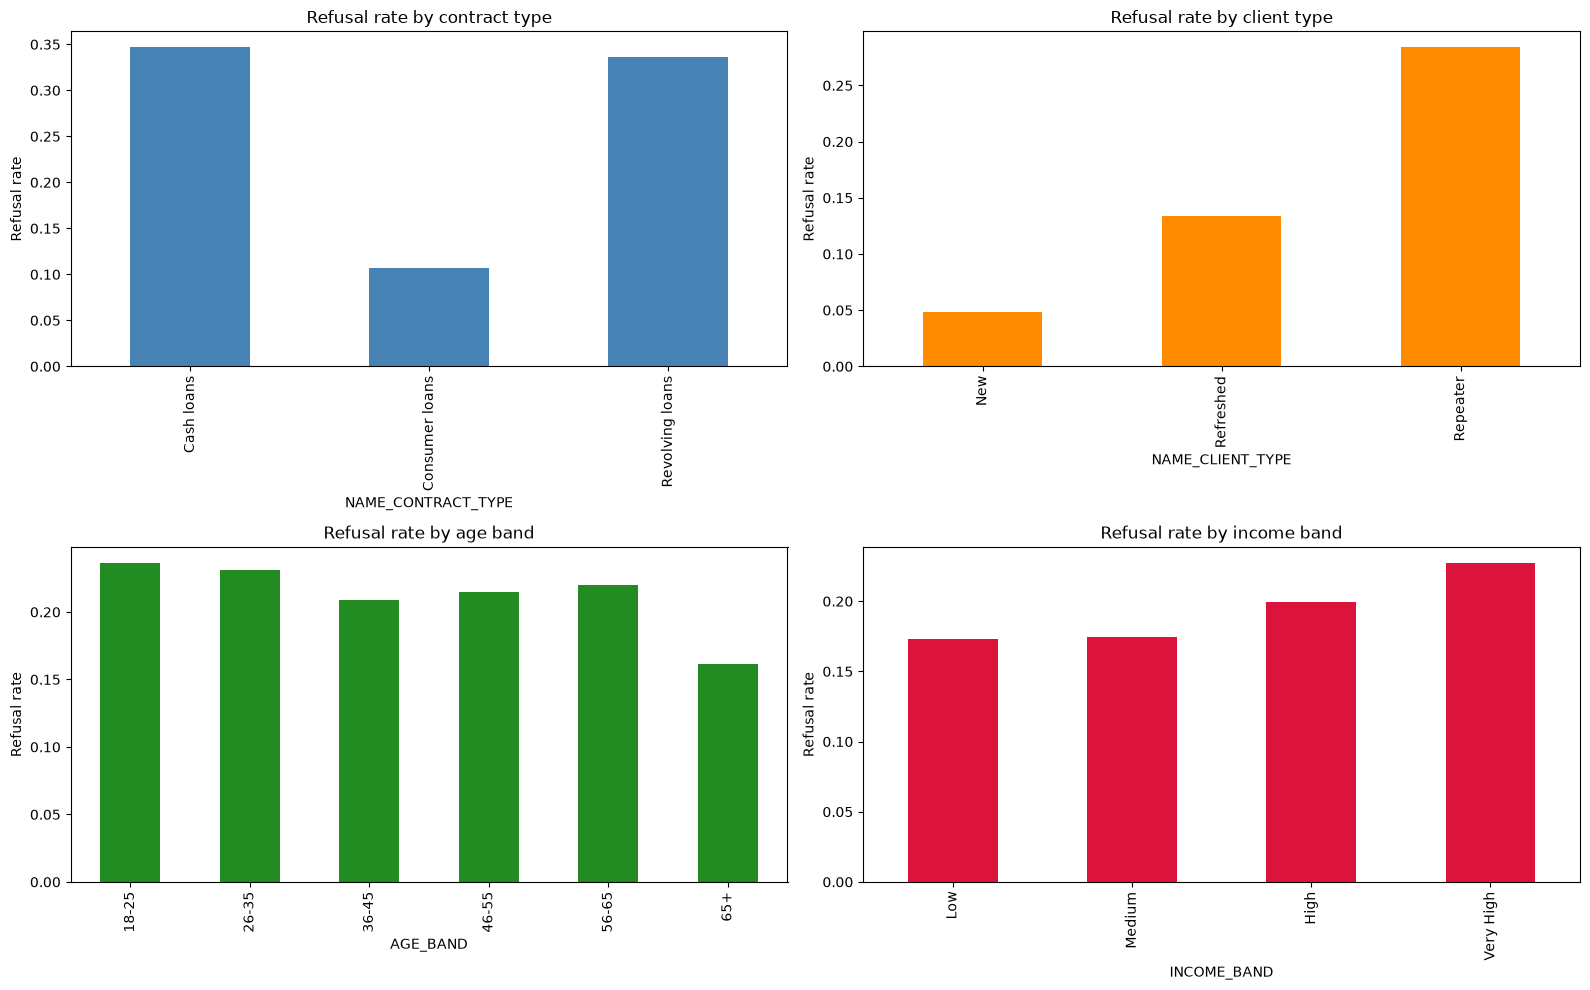

In [12]:
# Part 3: EDA and data model preparation

# Univariate and bivariate analysis across key dimensions.
refusal_by_channel = df.groupby("NAME_CLIENT_TYPE", dropna=False)["REFUSED"].mean().sort_values(ascending=False)
print("Refusal rate by client type:")
print(refusal_by_channel)

refusal_by_product = df.groupby("NAME_CONTRACT_TYPE", dropna=False)["REFUSED"].mean().sort_values(ascending=False)
print("\nRefusal rate by contract type:")
print(refusal_by_product)

insights = []
insights.append(
    f"Refusal rate for {refusal_by_channel.index[0]} is {refusal_by_channel.iloc[0]:.2%}, compared with {refusal_by_channel.iloc[-1]:.2%} for {refusal_by_channel.index[-1]}."
)
insights.append(
    f"Refusal rate by contract type is {refusal_by_product.iloc[0]:.2%} for {refusal_by_product.index[0]}, versus {refusal_by_product.iloc[-1]:.2%} for {refusal_by_product.index[-1]}."
)

if "NAME_INCOME_TYPE" in df.columns:
    income_refusal = df.groupby("NAME_INCOME_TYPE", dropna=False)["REFUSED"].mean().sort_values(ascending=False)
    insights.append(
        f"Income type analysis shows {income_refusal.index[0]} has a refusal rate of {income_refusal.iloc[0]:.2%}, compared with {income_refusal.index[-1]} at {income_refusal.iloc[-1]:.2%}."
    )

if "CODE_GENDER" in df.columns:
    gender_refusal = df.groupby("CODE_GENDER", dropna=False)["REFUSED"].mean().sort_values(ascending=False)
    insights.append(
        f"Gender-based refusal differs from {gender_refusal.index[0]} at {gender_refusal.iloc[0]:.2%} to {gender_refusal.index[-1]} at {gender_refusal.iloc[-1]:.2%}."
    )

if "AGE_BAND" in df.columns:
    age_refusal = df.groupby("AGE_BAND", dropna=False)["REFUSED"].mean().sort_values(ascending=False)
    insights.append(
        f"The age band {age_refusal.index[0]} shows the highest refusal rate at {age_refusal.iloc[0]:.2%}, compared with {age_refusal.index[-1]} at {age_refusal.iloc[-1]:.2%}."
    )

if "DAYS_DECISION" in df.columns:
    trend = df.assign(decision_month=(df["DAYS_DECISION"] / -30).round()).groupby("decision_month")["REFUSED"].mean()
    print("\nRefusal trend by decision month proxy:")
    print(trend.head())

print("\nBusiness insights:")
for i, insight in enumerate(insights, start=1):
    print(f"{i}. {insight}")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

if "NAME_CONTRACT_TYPE" in df.columns:
    df.groupby("NAME_CONTRACT_TYPE")["REFUSED"].mean().plot(kind="bar", ax=axes[0, 0], color="steelblue")
    axes[0, 0].set_title("Refusal rate by contract type")
    axes[0, 0].set_ylabel("Refusal rate")

if "NAME_CLIENT_TYPE" in df.columns:
    df.groupby("NAME_CLIENT_TYPE")["REFUSED"].mean().plot(kind="bar", ax=axes[0, 1], color="darkorange")
    axes[0, 1].set_title("Refusal rate by client type")
    axes[0, 1].set_ylabel("Refusal rate")

if "AGE_BAND" in df.columns:
    df.groupby("AGE_BAND")["REFUSED"].mean().plot(kind="bar", ax=axes[1, 0], color="forestgreen")
    axes[1, 0].set_title("Refusal rate by age band")
    axes[1, 0].set_ylabel("Refusal rate")

if "INCOME_BAND" in df.columns:
    df.groupby("INCOME_BAND")["REFUSED"].mean().plot(kind="bar", ax=axes[1, 1], color="crimson")
    axes[1, 1].set_title("Refusal rate by income band")
    axes[1, 1].set_ylabel("Refusal rate")

plt.tight_layout()
plt.show()


In [13]:
# Part 4: Model development

model_df = df.copy()
older = model_df[model_df["DAYS_DECISION"] <= -365].copy()
oot = model_df[model_df["DAYS_DECISION"] > -365].copy()

exclude_cols = [
    "REFUSED",
    "SK_ID_CURR",
    "SK_ID_PREV",
    "NAME_CONTRACT_STATUS",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_DECISION",
    "AGE_BAND",
    "INCOME_BAND",
    "EMPLOYMENT_BAND",
]

feature_cols = [
    c for c in older.columns
    if c not in exclude_cols and older[c].notna().any()
]

numeric_features = [c for c in feature_cols if pd.api.types.is_numeric_dtype(older[c])]
categorical_features = [c for c in feature_cols if c not in numeric_features]

X_old = older[feature_cols]
y_old = older["REFUSED"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X_old,
    y_old,
    test_size=0.30,
    random_state=42,
    stratify=y_old,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp,
)

X_oot = oot[feature_cols]
y_oot = oot["REFUSED"]

print(f"Train rows: {len(X_train)}")
print(f"Validation rows: {len(X_val)}")
print(f"Test rows: {len(X_test)}")
print(f"OOT rows: {len(X_oot)}")

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_features,
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_features,
        ),
    ]
)

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", min_samples_leaf=20, n_jobs=-1),
}

results = []
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)

    val_prob = pipeline.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    results.append({
        "model": name,
        "val_roc_auc": roc_auc_score(y_val, val_prob),
        "val_pr_auc": average_precision_score(y_val, val_prob),
        "val_precision": precision_score(y_val, val_pred, zero_division=0),
        "val_recall": recall_score(y_val, val_pred, zero_division=0),
        "val_f1": f1_score(y_val, val_pred, zero_division=0),
    })

print("Validation results:")
print(pd.DataFrame(results).sort_values("val_roc_auc", ascending=False).reset_index(drop=True))


Train rows: 714467
Validation rows: 153100
Test rows: 153101
OOT rows: 306791
Validation results:
                 model  val_roc_auc  val_pr_auc  val_precision  val_recall  \
0        Random Forest     0.970278    0.918214       0.711468    0.899796   
1  Logistic Regression     0.962074    0.896587       0.673725    0.882749   

     val_f1  
0  0.794626  
1  0.764202  


In [15]:
# Part 5: Evaluation, threshold selection and final model scoring

results_df = pd.DataFrame(results)
best_model_name = results_df.loc[results_df["val_roc_auc"].idxmax(), "model"]
print(f"Best validation model by ROC-AUC: {best_model_name}")

best_model = models[best_model_name]
final_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", best_model),
])
final_pipeline.fit(X_train, y_train)

validation_prob = final_pipeline.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.1, 0.9, 81)

best_threshold = 0.5
best_score = -1
best_metrics = None

for thr in thresholds:
    pred = (validation_prob >= thr).astype(int)
    precision = precision_score(y_val, pred, zero_division=0)
    recall = recall_score(y_val, pred, zero_division=0)
    f1 = f1_score(y_val, pred, zero_division=0)
    if f1 > best_score:
        best_score = f1
        best_threshold = thr
        best_metrics = {"threshold": thr, "precision": precision, "recall": recall, "f1": f1}

print("Best threshold chosen on validation:", best_threshold)
print(best_metrics)

for split_name, X_split, y_split in [("test", X_test, y_test), ("oot", X_oot, y_oot)]:
    probs = final_pipeline.predict_proba(X_split)[:, 1]
    pred = (probs >= best_threshold).astype(int)
    print(f"\n{split_name.upper()} confusion matrix")
    print(confusion_matrix(y_split, pred))
    print(f"ROC-AUC: {roc_auc_score(y_split, probs):.4f}")
    print(f"PR-AUC: {average_precision_score(y_split, probs):.4f}")
    print(f"Precision: {precision_score(y_split, pred, zero_division=0):.4f}")
    print(f"Recall: {recall_score(y_split, pred, zero_division=0):.4f}")
    print(f"F1: {f1_score(y_split, pred, zero_division=0):.4f}")

score_df = pd.DataFrame({
    "probability": final_pipeline.predict_proba(X_test)[:, 1],
    "actual": y_test.reset_index(drop=True),
})
score_df["risk_band"] = pd.cut(
    score_df["probability"],
    bins=[0, 0.25, 0.5, 0.75, 1.0],
    labels=["Low", "Medium", "High", "Very High"],
    include_lowest=True,
)
print("\nRisk band refusal rate on test set:")
print(score_df.groupby("risk_band")["actual"].mean())

out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)
model_path = Path("models")
model_path.mkdir(exist_ok=True)

import joblib
joblib.dump(final_pipeline, model_path / "final_model.joblib")
print("Saved final model to models/final_model.joblib")
print("Saved outputs to outputs/")


Best validation model by ROC-AUC: Random Forest
Best threshold chosen on validation: 0.69
{'threshold': np.float64(0.69), 'precision': 0.8515275191187542, 'recall': 0.8122921076504385, 'f1': 0.8314471978797903}

TEST confusion matrix
[[122811   3834]
 [  5037  21419]]
ROC-AUC: 0.9696
PR-AUC: 0.9167
Precision: 0.8482
Recall: 0.8096
F1: 0.8284

OOT confusion matrix
[[184203   8282]
 [ 34916  79390]]
ROC-AUC: 0.9485
PR-AUC: 0.9225
Precision: 0.9055
Recall: 0.6945
F1: 0.7861

Risk band refusal rate on test set:
risk_band
Low          0.013197
Medium       0.117493
High         0.338748
Very High    0.893134
Name: actual, dtype: float64
Saved final model to models/final_model.joblib
Saved outputs to outputs/
